# 2026-06-29 DNA Quantification — 2 samples (Portelite BDR / Qubit)

Qubit green-channel readings taken on **2026-06-29** for **2 samples**, prepared by different
methods (per user). **Sample 2 was read at a 50 % dilution**, so its original (undiluted)
concentration is back-calculated (× 2) at the end.

**Kit:** Portelite™ Fluorimetric DNA Quantitation Kit, Broad Dynamic Range (AAT Bioquest 17665),
Ex/Em 480/530 nm, green channel — same assay/method as
[`0622_quantification.ipynb`](0622_quantification.ipynb). A fresh 6-point standard curve
(S0–S100) was read this session; samples are inverted on it by linear regression after
blank subtraction.

**Three sections:** (1) build the standard curve, (2) convert each reading to ng/µL — including
the original concentration of the diluted Sample 2, (3) DNA mass remaining per tube.

## Notes (read before trusting any number)
- **Per-sample dilution:** Sample 1 read **undiluted** (factor 1); Sample 2 read at **50 %**
  (factor 2 → original = as-read × 2). Set in the `samples` table below.
- **Sample IDs are raw green-channel RFU** (same scale as the standards).
- Both readings sit **below the S100 top standard (21,544 RFU)**, so no extrapolation is needed.
- **Mass assumption (Section 3):** remaining volume is taken to hold the sample at its **original
  concentration** (Sample 1: 54 µL; Sample 2: 19 µL). If the 19 µL you have left is the *already-
  diluted* Sample 2 rather than original stock, use the *as-read* concentration instead → halve
  that mass. Flagged so it's easy to switch.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

DATE = '2026-06-29'
OUTPUT_DIR = 'output/0629_quantification'
os.makedirs(OUTPUT_DIR, exist_ok=True)

## Section 1 — Build the standard curve

Fresh 6-point series read this session (S0 blank → S100). Subtract the Std-0 blank RFU from
every reading, then fit `RFU_corrected = slope · conc + intercept` by linear regression. Report
slope, intercept and R².

In [2]:
# Standards (ng/uL, raw green-channel RFU) -- read 2026-06-29
standards = pd.DataFrame({
    'standard':   ['Std 0 (blank)', 'Std 1', 'Std 3', 'Std 10', 'Std 30', 'Std 100'],
    'conc_ng_uL': [0.0, 1.0, 3.0, 10.0, 30.0, 100.0],
    'rfu':        [148.72, 359.54, 862.17, 2073.23, 6390.88, 21543.99],
})

BLANK_RFU = standards.loc[standards['conc_ng_uL'] == 0, 'rfu'].iloc[0]
standards['rfu_corrected'] = standards['rfu'] - BLANK_RFU

# Linear regression: rfu_corrected = slope * conc + intercept
slope, intercept = np.polyfit(standards['conc_ng_uL'], standards['rfu_corrected'], 1)
fit = slope * standards['conc_ng_uL'] + intercept
ss_res = np.sum((standards['rfu_corrected'] - fit) ** 2)
ss_tot = np.sum((standards['rfu_corrected'] - standards['rfu_corrected'].mean()) ** 2)
r_squared = 1 - ss_res / ss_tot

MAX_STD_CONC = standards['conc_ng_uL'].max()  # 100 ng/uL -> above this = extrapolated

print(f'Blank (Std 0) RFU : {BLANK_RFU:.2f}')
print(f'Slope            : {slope:.4f} RFU per ng/uL')
print(f'Intercept        : {intercept:.4f} RFU')
print(f'R^2              : {r_squared:.6f}')
standards

Blank (Std 0) RFU : 148.72
Slope            : 214.0216 RFU per ng/uL
Intercept        : -55.4830 RFU
R^2              : 0.999812


,standard,conc_ng_uL,rfu,rfu_corrected
0,Std 0 (blank),0.0,148.72,0.00
1,Std 1,1.0,359.54,210.82
2,Std 3,3.0,862.17,713.45
3,Std 10,10.0,2073.23,1924.51
4,Std 30,30.0,6390.88,6242.16
5,Std 100,100.0,21543.99,21395.27


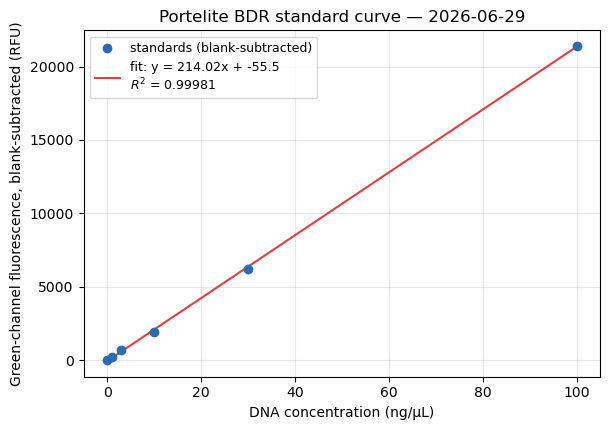

In [3]:
# Conversion helper: invert the fitted line -> AS-READ concentration (no dilution applied).
def rfu_to_conc(rfu):
    """Raw green-channel RFU -> DNA concentration (ng/uL) in the assay tube (as read)."""
    return (np.asarray(rfu, dtype=float) - BLANK_RFU - intercept) / slope

# Plot the standard curve with the fit
fig, ax = plt.subplots(figsize=(6.2, 4.4))
ax.scatter(standards['conc_ng_uL'], standards['rfu_corrected'],
           color='#2b6cb0', zorder=3, label='standards (blank-subtracted)')
xline = np.linspace(0, MAX_STD_CONC, 100)
ax.plot(xline, slope * xline + intercept, color='#e53e3e', lw=1.5,
        label=f'fit: y = {slope:.2f}x + {intercept:.1f}\n$R^2$ = {r_squared:.5f}')
ax.set_xlabel('DNA concentration (ng/µL)')
ax.set_ylabel('Green-channel fluorescence, blank-subtracted (RFU)')
ax.set_title('Portelite BDR standard curve — 2026-06-29')
ax.legend(loc='upper left', fontsize=9); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, f'{DATE}_standard-curve.png'), dpi=150, bbox_inches='tight')
plt.show()

## Section 2 — Sample DNA concentrations

`as_read` = concentration in the assay tube from the curve. `original` = `as_read × dilution_factor`
(Sample 2 was read at 50 %, so its dilution factor is 2; Sample 1 is undiluted, factor 1).

In [4]:
# Raw green-channel readings, 2026-06-29. dilution_factor: 1 = undiluted, 2 = read at 50 %.
samples = pd.DataFrame([
    ('Sample 1', 517.73,  1, 54.0),   # undiluted
    ('Sample 2', 3116.15, 2, 19.0),   # read at 50 % dilution -> original = as-read x 2
], columns=['sample', 'rfu', 'dilution_factor', 'remaining_vol_uL'])

samples['conc_as_read'] = rfu_to_conc(samples['rfu'])
samples['conc_original'] = samples['conc_as_read'] * samples['dilution_factor']
samples['extrapolated'] = samples['rfu'] > standards['rfu'].max()

with pd.option_context('display.float_format', lambda v: f'{v:,.3f}'):
    print(samples[['sample', 'rfu', 'dilution_factor',
                   'conc_as_read', 'conc_original', 'extrapolated']].to_string(index=False))

s2 = samples.loc[samples['sample'] == 'Sample 2'].iloc[0]
print(f"\nSample 2 was read at 50 % dilution:")
print(f"  as-read concentration  : {s2['conc_as_read']:.3f} ng/uL")
print(f"  ORIGINAL concentration : {s2['conc_original']:.3f} ng/uL  (= as-read x 2)")

  sample       rfu  dilution_factor  conc_as_read  conc_original  extrapolated
Sample 1   517.730                1         1.983          1.983         False
Sample 2 3,116.150                2        14.124         28.249         False

Sample 2 was read at 50 % dilution:
  as-read concentration  : 14.124 ng/uL
  ORIGINAL concentration : 28.249 ng/uL  (= as-read x 2)


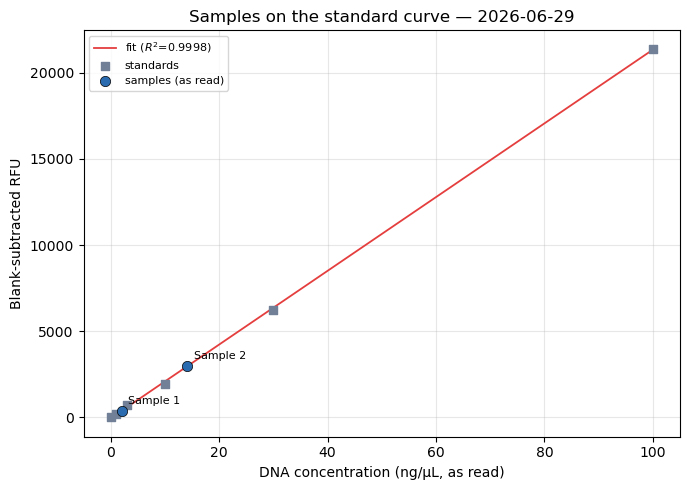

In [5]:
# Place both samples on the standard curve (at AS-READ concentration, blank-subtracted RFU).
fig, ax = plt.subplots(figsize=(7.0, 5.0))
xs = np.linspace(0, MAX_STD_CONC, 100)
ax.plot(xs, slope * xs + intercept, color='#e53e3e', lw=1.3, zorder=2,
        label=f'fit ($R^2$={r_squared:.4f})')
ax.scatter(standards['conc_ng_uL'], standards['rfu_corrected'], color='#718096',
           marker='s', s=40, zorder=3, label='standards')
ax.scatter(samples['conc_as_read'], samples['rfu'] - BLANK_RFU, color='#2b6cb0', s=55,
           zorder=4, edgecolor='black', linewidth=0.5, label='samples (as read)')
for _, r in samples.iterrows():
    ax.annotate(r['sample'], (r['conc_as_read'], r['rfu'] - BLANK_RFU),
                textcoords='offset points', xytext=(5, 5), fontsize=8)
ax.set_xlabel('DNA concentration (ng/µL, as read)')
ax.set_ylabel('Blank-subtracted RFU')
ax.set_title('Samples on the standard curve — 2026-06-29')
ax.legend(fontsize=8, loc='upper left'); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, f'{DATE}_samples-on-curve.png'), dpi=150, bbox_inches='tight')
plt.show()

## Section 3 — DNA mass remaining per tube

`mass = original concentration (ng/µL) × remaining volume (µL)`, in µg. Remaining volumes:
Sample 1 = 54 µL, Sample 2 = 19 µL. (See the mass assumption in the notes above.)

In [6]:
samples['mass_ug'] = samples['conc_original'] * samples['remaining_vol_uL'] / 1000.0

with pd.option_context('display.float_format', lambda v: f'{v:,.4f}'):
    print(samples[['sample', 'conc_original', 'remaining_vol_uL', 'mass_ug']].to_string(index=False))

print(f"\nTotal DNA remaining across both tubes: {samples['mass_ug'].sum():,.4f} ug "
      f"({samples['mass_ug'].sum()*1000:,.1f} ng)")

samples.to_csv(os.path.join(OUTPUT_DIR, f'{DATE}_quantification.csv'), index=False)
print(f"saved -> {os.path.join(OUTPUT_DIR, f'{DATE}_quantification.csv')}")

  sample  conc_original  remaining_vol_uL  mass_ug
Sample 1         1.9834           54.0000   0.1071
Sample 2        28.2487           19.0000   0.5367

Total DNA remaining across both tubes: 0.6438 ug (643.8 ng)
saved -> output/0629_quantification/2026-06-29_quantification.csv


## Section 4 — Dilute Sample 2 to 10–11 ng/µL (add diluent to the original tube)

Sample 2's original tube holds **19 µL at its original concentration (≈28.25 ng/µL)**. DNA mass is
conserved when you only add diluent, so `C1·V1 = C2·V2`: the final volume `V2 = C1·V1 / C2`, and the
**diluent to add = V2 − V1**. A higher target (11) needs less diluent; a lower target (10) needs more.

In [7]:
# ---- how much diluent to ADD to Sample 2's original tube to reach 10-11 ng/uL ----
TARGET_LOW, TARGET_HIGH = 10.0, 11.0   # desired final concentration window (ng/uL)

s2 = samples.loc[samples['sample'] == 'Sample 2'].iloc[0]
C1 = s2['conc_original']          # current conc in the original tube (ng/uL)
V1 = s2['remaining_vol_uL']       # current volume in the original tube (uL)

print(f"Sample 2 original tube: {V1:.0f} uL at {C1:.2f} ng/uL  (total {C1*V1:.1f} ng of DNA)")
print("Add diluent (nuclease-free water / elution buffer) INTO the tube:\n")
print(f"{'target (ng/uL)':>14} | {'final vol (uL)':>14} | {'diluent to ADD (uL)':>20}")
print('-' * 54)
for C2 in [TARGET_HIGH, 10.5, TARGET_LOW]:
    V2 = C1 * V1 / C2             # C1*V1 = C2*V2  (mass conserved)
    print(f"{C2:>14.1f} | {V2:>14.2f} | {V2 - V1:>20.2f}")

add_for_high = C1 * V1 / TARGET_HIGH - V1   # -> 11 ng/uL (least diluent)
add_for_low  = C1 * V1 / TARGET_LOW  - V1   # -> 10 ng/uL (most diluent)
print(f"\n=> Add between {add_for_high:.1f} uL (lands at {TARGET_HIGH:.0f} ng/uL) and "
      f"{add_for_low:.1f} uL (lands at {TARGET_LOW:.0f} ng/uL) of diluent to the {V1:.0f} uL tube.")
print(f"   A safe single value: add ~{(add_for_high+add_for_low)/2:.0f} uL -> "
      f"~{C1*V1/(V1+(add_for_high+add_for_low)/2):.1f} ng/uL (within 10-11).")

Sample 2 original tube: 19 uL at 28.25 ng/uL  (total 536.7 ng of DNA)
Add diluent (nuclease-free water / elution buffer) INTO the tube:

target (ng/uL) | final vol (uL) |  diluent to ADD (uL)
------------------------------------------------------
          11.0 |          48.79 |                29.79
          10.5 |          51.12 |                32.12
          10.0 |          53.67 |                34.67

=> Add between 29.8 uL (lands at 11 ng/uL) and 34.7 uL (lands at 10 ng/uL) of diluent to the 19 uL tube.
   A safe single value: add ~32 uL -> ~10.5 ng/uL (within 10-11).


## Section 5 — Dilution performed (Sample 2)

Recorded as run: **25 µL of nuclease-free water added** to Sample 2's original tube
(19 µL @ ≈28.25 ng/µL) → final volume 44 µL. Final concentration computed below from
`C1·V1 = C2·V2`. (Note: this lands slightly **above** the 10–11 ng/µL target.)

In [8]:
# ---- actual dilution performed on Sample 2 ----
WATER_ADDED_uL = 25.0    # nuclease-free water added to the original tube

s2 = samples.loc[samples['sample'] == 'Sample 2'].iloc[0]
C1 = s2['conc_original']            # 28.25 ng/uL
V1 = s2['remaining_vol_uL']         # 19 uL
V_final = V1 + WATER_ADDED_uL
C_final = C1 * V1 / V_final         # mass conserved

print(f"Sample 2: added {WATER_ADDED_uL:.0f} uL nuclease-free water "
      f"to {V1:.0f} uL @ {C1:.2f} ng/uL")
print(f"  final volume        : {V_final:.0f} uL")
print(f"  final concentration : {C_final:.2f} ng/uL")
print(f"  (target was 10-11 ng/uL -> this is "
      f"{'within' if 10 <= C_final <= 11 else 'slightly above' if C_final > 11 else 'below'} range)")

Sample 2: added 25 uL nuclease-free water to 19 uL @ 28.25 ng/uL
  final volume        : 44 uL
  final concentration : 12.20 ng/uL
  (target was 10-11 ng/uL -> this is slightly above range)


## Readout

- **Curve:** fresh 6-point S0–S100 series; linear fit + R² in Section 1.
- **Sample 1** (undiluted): see `conc_original` (= `conc_as_read`).
- **Sample 2** (read at 50 % dilution): as-read concentration doubled → **original concentration**
  reported in Section 2; both readings are within the curve (no extrapolation).
- **Mass remaining:** Section 3 (Sample 1 at 54 µL, Sample 2 at 19 µL).

---
*Log: created 2026-06-29 from bench Qubit readings (2 samples, different prep methods; Sample 2 read at 50 % dilution → original concentration back-calculated × 2). Remaining volumes 54 µL (S1) / 19 µL (S2) per user. Outputs in `output/0629_quantification/`.*
*Log: 2026-06-29 — added Section 4: diluent volume to bring Sample 2's original tube (19 µL @ 28.25 ng/µL) into the 10–11 ng/µL range (C1·V1 = C2·V2).*
*Log: 2026-06-29 — added Section 5: recorded the dilution performed — 25 µL nuclease-free water into Sample 2's 19 µL tube → 44 µL final, ≈12.2 ng/µL.*